# Day 3: YOLOX-S training, MLflow, gate and R2

Run cells in order. Start with **cpu_smoke**, then use **full_gpu** for all-data
training. Full runs use **30 epochs, batch 16**; smoke uses **2 epochs, batch 2**.
Both export and upload. Only a full candidate with higher validation AP and
passing parity/image acceptance can replace the champion.

Use newly rotated R2 keys in Colab Secrets. Full runs require the final Day 2
model manifest in R2 (Day 2 Section 13). No Comet/MLflow account is required.
Actual cloud installation/training and trigger behavior must be checked in your
runtime; the package's offline tests do not measure model quality.


## 1. Recreate the project files
This cell contains the source. Run it after each runtime reset.


In [1]:
import base64, gzip, json, os, sys
from pathlib import Path, PurePosixPath

PROJECT = Path('/content/signature_day3')
PROJECT.mkdir(parents=True, exist_ok=True)
PACKED = '...'
payload = json.loads(gzip.decompress(base64.b64decode(PACKED)))
for relative, value in payload.items():
    item = PurePosixPath(relative)
    if item.is_absolute() or '..' in item.parts or '\\' in relative:
        raise ValueError('Unsafe embedded source path')
    target = PROJECT.joinpath(*item.parts)
    content = base64.b64decode(value)
    if target.is_file() and target.read_bytes() != content:
        raise RuntimeError('Existing source differs: '+str(target)+'. Preserve edits and choose a new PROJECT directory.')
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)
print('Project ready:', PROJECT)
print('Source files:', len(payload))


Project ready: /content/signature_day3
Source files: 38


## 2. Choose a profile and load private secrets

In Colab's key sidebar add R2_ACCOUNT_ID, R2_ACCESS_KEY_ID,
R2_SECRET_ACCESS_KEY, R2_BUCKET; enable notebook access. HF_TOKEN is optional.
Set `PROFILE='full_gpu'` after choosing a permitted GPU runtime.

For recovery, paste your original printed RUN_ID into `RUN_ID` and set RESUME=True.
Keep the same profile, target epochs and batch size. A new fresh run uses a new ID.


In [3]:
import os
import sys
from pathlib import Path
from google.colab import userdata

PROJECT = Path('/content/signature_day3')

if not (PROJECT / 'train_day3.py').is_file():
    raise RuntimeError(
        'Run Day 3 Section 1 first to recreate the project files.'
    )

# New CPU integration test
PROFILE = 'cpu_smoke'
RESUME = False
RUN_ID = 'signature_day3_cpu_smoke_e2_b2_20261109'

DATASET_REVISION = 'a55352328a1fbc3442b54db0e377f5add470bcba'

DEVICE = 'cpu'
EPOCHS = 2
BATCH_SIZE = 2

OUT = PROJECT / 'outputs' / RUN_ID

# Load credentials from Colab Secrets
required = (
    'R2_ACCOUNT_ID',
    'R2_ACCESS_KEY_ID',
    'R2_SECRET_ACCESS_KEY',
    'R2_BUCKET',
)

values = {}
missing = []

for name in required:
    try:
        value = (userdata.get(name) or '').strip()
    except (
        userdata.SecretNotFoundError,
        userdata.NotebookAccessError,
    ):
        value = ''

    if value:
        values[name] = value
    else:
        missing.append(name)

if missing:
    raise ValueError(
        'Add these Colab Secrets and enable Notebook access: '
        + ', '.join(missing)
    )

os.environ.update(values)

# Optional Hugging Face token
try:
    token = userdata.get('HF_TOKEN')
    if token:
        os.environ['HF_TOKEN'] = token.strip()
except (
    userdata.SecretNotFoundError,
    userdata.NotebookAccessError,
):
    pass

print('SAVE THIS RUN ID:', RUN_ID)
print('Profile:', PROFILE, '| resume:', RESUME)
print('Device:', DEVICE)
print('Target epochs:', EPOCHS, '| batch size:', BATCH_SIZE)
print('Subset limits: 32 train | 16 validation | 16 test images')
print('Every-epoch checkpoints: R2')
print('Experiment tracking: MLflow with R2 backups')
print('Production promotion: disabled for smoke runs')
print('Output:', OUT)

SAVE THIS RUN ID: signature_day3_cpu_smoke_e2_b2_20261109
Profile: cpu_smoke | resume: False
Device: cpu
Target epochs: 2 | batch size: 2
Subset limits: 32 train | 16 validation | 16 test images
Every-epoch checkpoints: R2
Experiment tracking: MLflow with R2 backups
Production promotion: disabled for smoke runs
Output: /content/signature_day3/outputs/signature_day3_cpu_smoke_e2_b2_20261109


## 3. Build the one command and print its plan
This cell does not train or download.


In [4]:
import subprocess

COMMAND = [sys.executable, '-u', str(PROJECT/'train_day3.py'),
    '--dataset', 'AimaArshad/signature-detection-yolox',
    '--dataset-revision', DATASET_REVISION, '--epochs', str(EPOCHS),
    '--batch-size', str(BATCH_SIZE), '--device', DEVICE,
    '--workers', '0', '--output', str(OUT)]
if PROFILE == 'cpu_smoke':
    COMMAND += ['--smoke','--train-limit','32','--val-limit','16','--test-limit','16']
if RESUME:
    COMMAND += ['--resume']
subprocess.run(COMMAND+['--dry-run'], cwd=PROJECT, check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/signature_day3/train_day3.py', '--dataset', 'AimaArshad/signature-detection-yolox', '--dataset-revision', 'a55352328a1fbc3442b54db0e377f5add470bcba', '--epochs', '2', '--batch-size', '2', '--device', 'cpu', '--workers', '0', '--output', '/content/signature_day3/outputs/signature_day3_cpu_smoke_e2_b2_20261109', '--smoke', '--train-limit', '32', '--val-limit', '16', '--test-limit', '16', '--dry-run'], returncode=0)

## 4. Train → export → evaluate → upload → gate

Run once and let it finish. Setup installs an isolated environment. Logs stream
below and are also saved locally. Completed checkpoints and MLflow metadata are
backed up to R2 each epoch. CPU smoke is bounded but is not instantaneous.
A full run first verifies/downloads and evaluates the baseline, then trains.

A `rejected` gate with passing acceptance is an expected result if the candidate
did not improve. Smoke never promotes, even if its subset AP is high.


In [7]:
def stream_command(command):
    OUT.mkdir(parents=True, exist_ok=True)
    log_path = OUT/'console.log'
    env = {**os.environ, 'PYTHONUNBUFFERED':'1'}
    process = subprocess.Popen(command, cwd=PROJECT, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding='utf-8', errors='replace', bufsize=1)
    try:
        with log_path.open('a', encoding='utf-8') as log:
            for line in process.stdout:
                print(line, end='', flush=True)
                log.write(line)
                log.flush()
        result = process.wait()
    except BaseException:
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        raise
    if result:
        raise subprocess.CalledProcessError(result, command)
    print('Command finished. Console log:', log_path)

stream_command(COMMAND)


/content/signature_day3/vendor/YOLOX/yolox/models/yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
Device: cpu | YOLOX forward/backward and NMS checks passed.
Isolated YOLOX environment ready. No Ultralytics package is used.
Recovered full checkpoint after epoch 2 from local
Smoke: downloading train2017.zip; extracting only 32 images.
Smoke: downloading val2017.zip; extracting only 16 images.
Smoke: downloading test2017.zip; extracting only 16 images.
Run: signature_day3_cpu_smoke_e2_b2_20261109 | device: cpu | smoke: True
Epochs: 2 | batch: 2 | split counts: {'train': 32, 'val': 16, 'test': 16}
Epoch 2 checkpoint verified: R2
2026-11-09 10:49:15.951 | INFO     | __main__:main:64 - args value: Namespace(output_name='/content/signature_day3/outputs/signature_day3_cpu_smoke_e2_b2_20261109/artifact/signature_yolox_s.pending.onnx', input='images', outpu

### Recovery for cell 4

In [6]:
import ast
import json
import shutil
import sys
from pathlib import Path

PROJECT = Path('/content/signature_day3')
RUN_ID = 'signature_day3_cpu_smoke_e2_b2_20261109'
OUT = PROJECT / 'outputs' / RUN_ID

saved = json.loads((OUT / 'config.json').read_text())

if saved.get('run_id') != RUN_ID or not saved.get('smoke'):
    raise ValueError('Expected your saved CPU smoke configuration.')

# Restore LICENSE from the pinned YOLOX source.
source_license = Path(saved['source_dir']) / 'LICENSE'

if not source_license.is_file():
    raise FileNotFoundError(str(source_license))

shutil.copy2(source_license, PROJECT / 'LICENSE')

# Preserve LICENSE when the script repacks the handoff ZIP.
script = PROJECT / 'train_day3.py'
text = script.read_text(encoding='utf-8')

old = (
    "if file.is_file() and file.suffix in "
    "('.onnx','.json','.py','.txt','.md'):"
)
new = (
    "if file.is_file() and (file.name == 'LICENSE' or file.suffix in "
    "('.onnx','.json','.py','.txt','.md')):"
)

if old in text:
    repaired = text.replace(old, new, 1)
    ast.parse(repaired)
    script.write_text(repaired, encoding='utf-8')
elif new not in text and 'package_handoff(artifact)' not in text:
    raise RuntimeError('Unexpected script version; retain your checkpoints.')

# Resume the SAME completed training run.
PROFILE = 'cpu_smoke'
RESUME = True
DEVICE = 'cpu'
EPOCHS = saved['epochs']
BATCH_SIZE = saved['batch_size']
DATASET_REVISION = saved['dataset_revision']
limits = saved['smoke_limits']

COMMAND = [
    sys.executable, '-u', str(PROJECT / 'train_day3.py'),
    '--dataset', saved['dataset_repo'],
    '--dataset-revision', DATASET_REVISION,
    '--epochs', str(EPOCHS),
    '--batch-size', str(BATCH_SIZE),
    '--device', 'cpu',
    '--workers', '0',
    '--output', str(OUT),
    '--r2-prefix', saved['r2_prefix'],
    '--registry-name', saved['registry_name'].removesuffix('-smoke'),
    '--smoke',
    '--train-limit', str(limits['train']),
    '--val-limit', str(limits['val']),
    '--test-limit', str(limits['test']),
    '--resume',
]

print('LICENSE restored and ZIP packaging repaired.')
print('Run ID:', RUN_ID)
print('Resume:', RESUME, '| epochs:', EPOCHS, '| batch:', BATCH_SIZE)
print('Now rerun Section 4.')

LICENSE restored and ZIP packaging repaired.
Run ID: signature_day3_cpu_smoke_e2_b2_20261109
Resume: True | epochs: 2 | batch: 2
Now rerun Section 4.


## 5. Review actual status, metrics and errors
Read gate reasons and acceptance before calling the model ready.


reports/day3_status.json
{
  "run_id": "signature_day3_cpu_smoke_e2_b2_20261109",
  "smoke": true,
  "status": "smoke_completed",
  "started_at_utc": "2026-11-09T10:48:55.697418+00:00",
  "gate": {
    "promote": false,
    "reasons": [
      "smoke_runs_cannot_promote",
      "positive_or_negative_acceptance_failed",
      "baseline_mAP50_missing_or_invalid"
    ],
    "metric": "validation_mAP50",
    "candidate_mAP50": 0.06506617950320459,
    "baseline_mAP50": null,
    "min_delta": 0.0,
    "comparison": "candidate > baseline + min_delta",
    "held_out_test_score_used_for_comparison": false
  },
  "mlflow_run_id": "22702f82b8974d4fa68cc10fcf30f37f",
  "candidate_uploaded": true,
  "model_version": null,
  "acceptance_passed": false,
  "finished_at_utc": "2026-11-09T10:50:23.516290+00:00"
}
reports/gate.json
{
  "promote": false,
  "reasons": [
    "smoke_runs_cannot_promote",
    "positive_or_negative_acceptance_failed",
    "baseline_mAP50_missing_or_invalid"
  ],
  "metric": "v

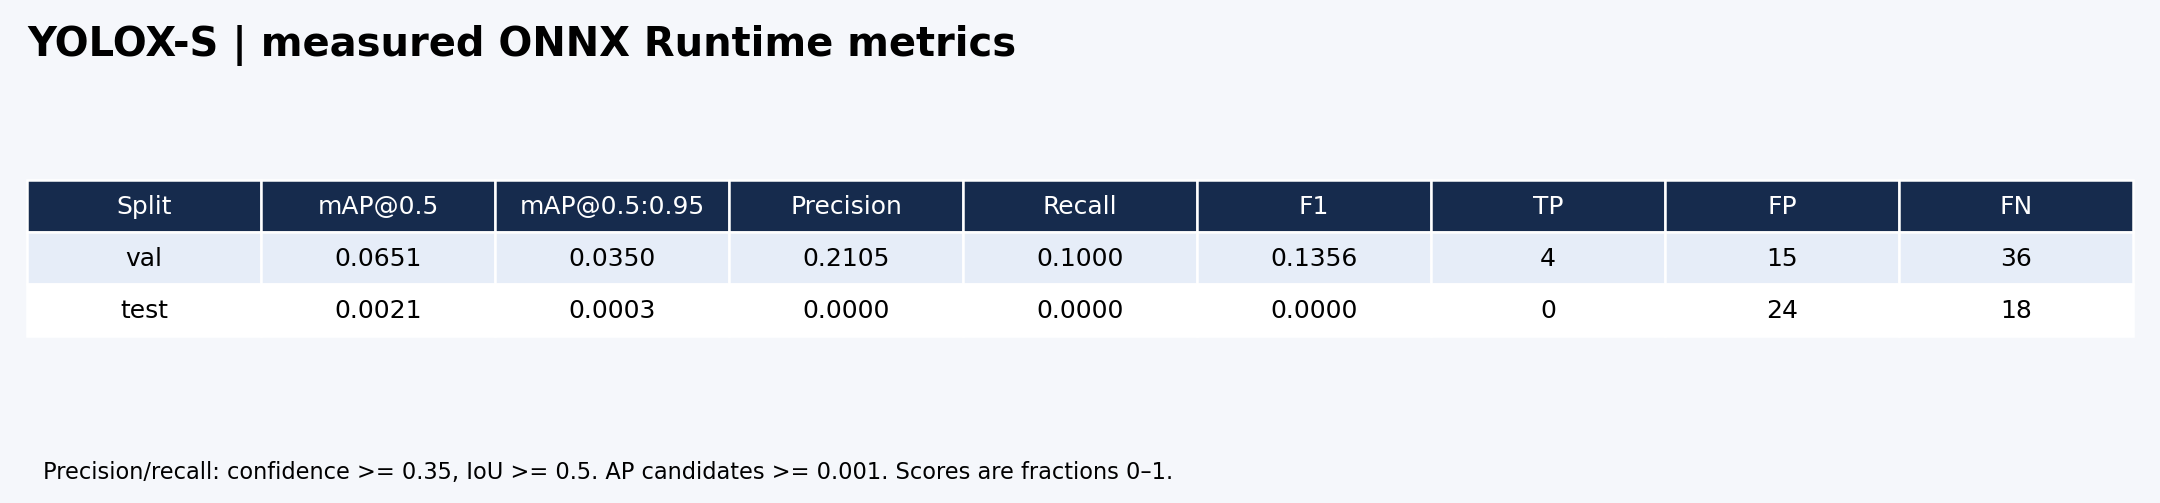

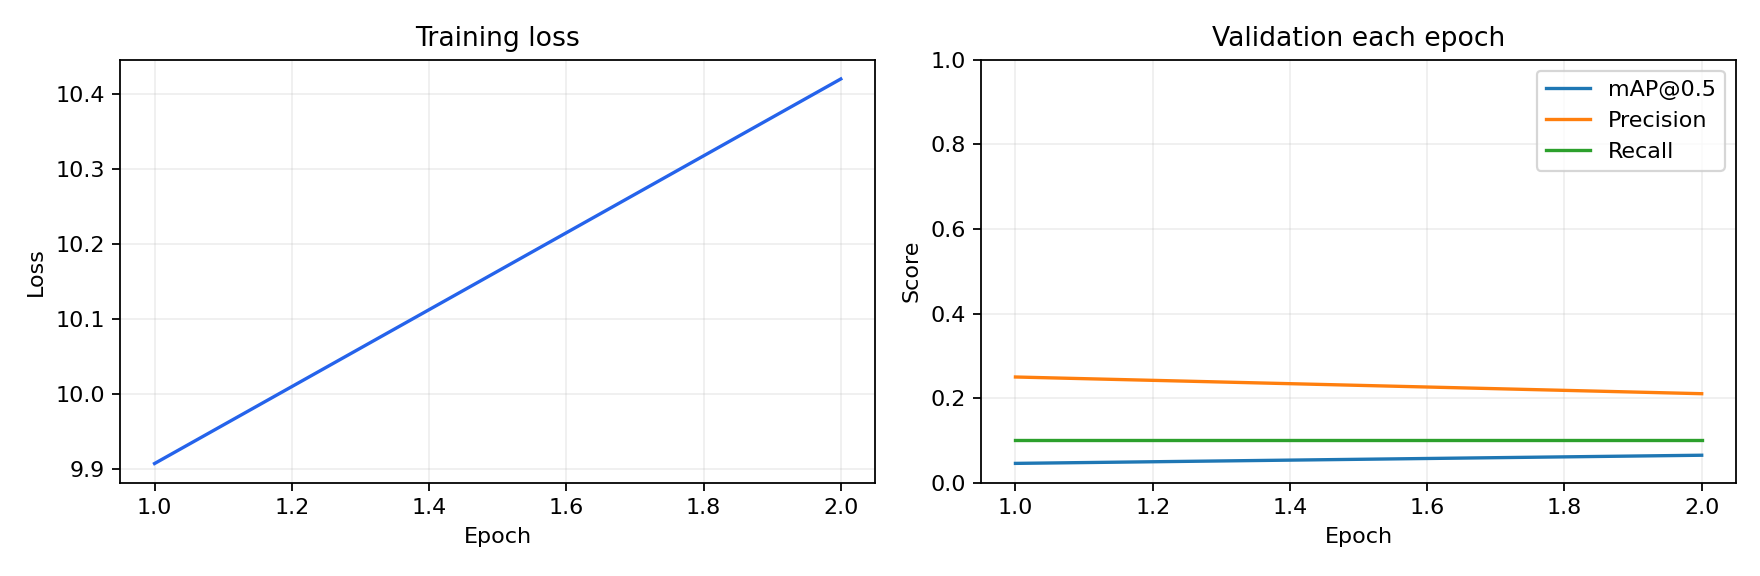

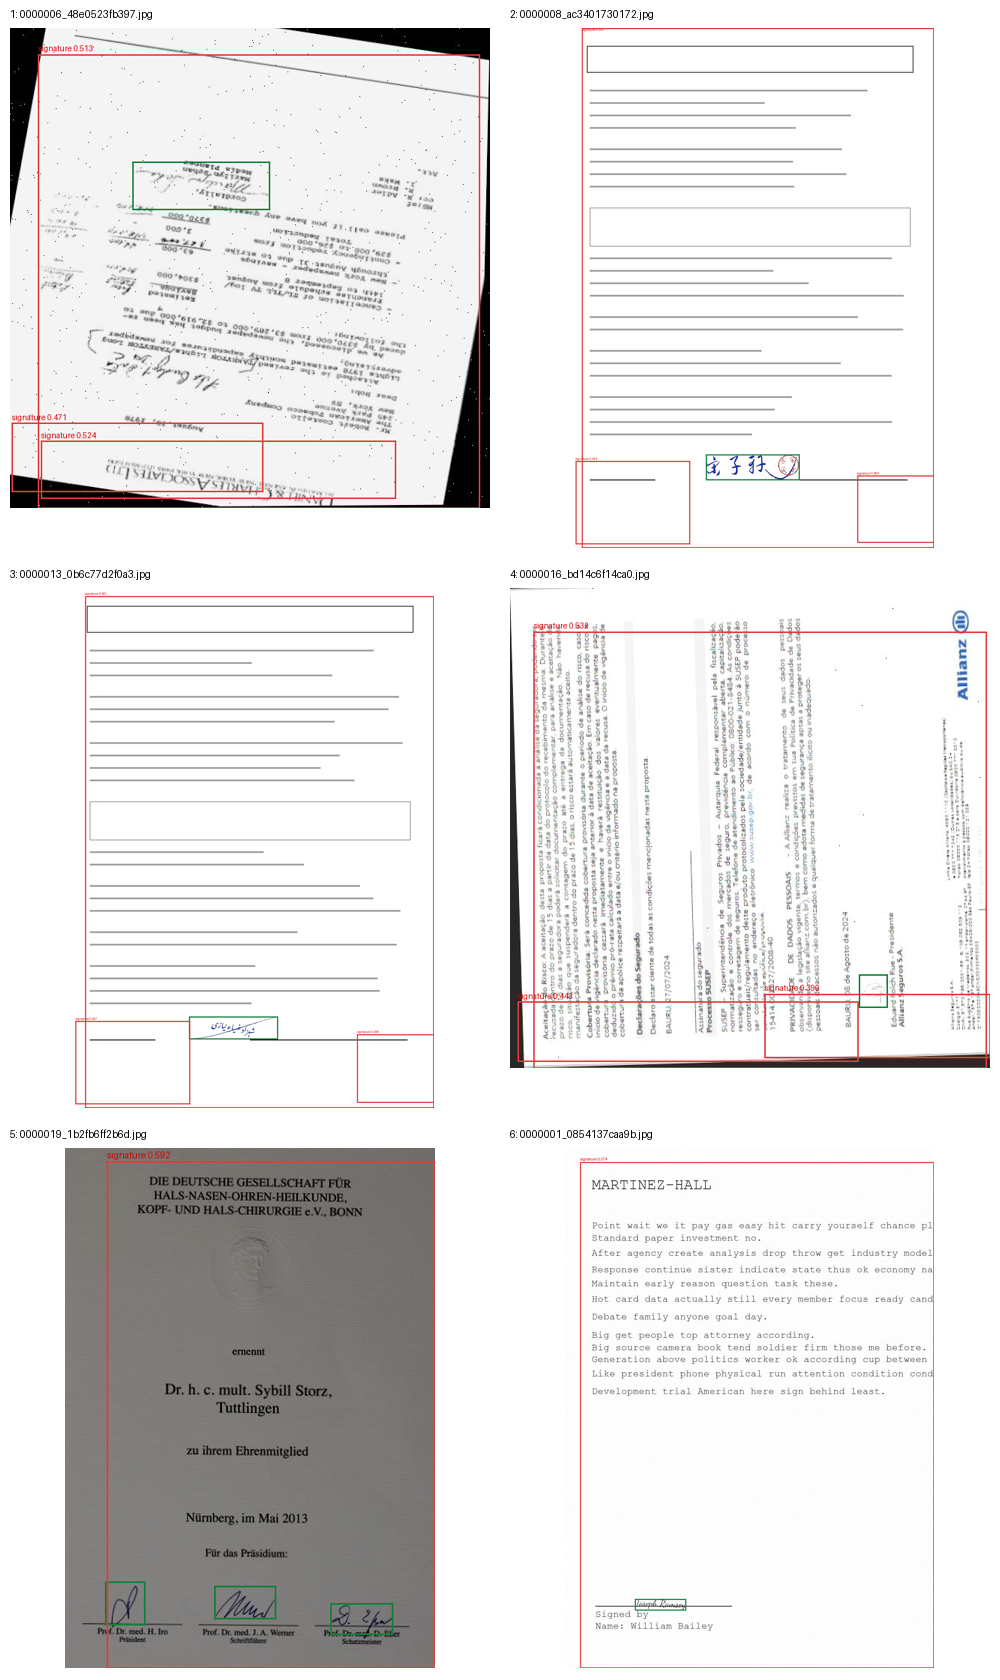

# Observed ONNX errors

Split: test; confidence=0.35; matching IoU=0.5.
Images with measured FP/FN: 16 / 16.

See errors.csv for every affected image. Red boxes = predictions; green = ground truth.

- missed_signature: 16 images
- false_positive_or_duplicate_or_poor_localization: 16 images

## Visual review prompts (hypotheses, not automatically proven causes)

- Small signatures reduced to very few pixels at 640.
- Faint ink, low contrast, blur or compression.
- Stamps, printed names, handwriting or form lines mistaken for signatures.
- Rotated pages, dense forms, overlapping signatures or unfamiliar templates.

Confirm these causes by inspecting examples; do not label them measured failure modes without evidence.


In [8]:
from IPython.display import display, Image as DisplayImage, Markdown
for relative in ('reports/day3_status.json','reports/gate.json','acceptance/acceptance_tests.json'):
    path = OUT/relative
    print(relative)
    if path.is_file():
        print(json.dumps(json.loads(path.read_text()), indent=2))
    else:
        print('Not produced; inspect the execution log.')
for relative in ('reports/metrics_table.png','reports/learning_curves.png','reports/error_examples.png'):
    if (OUT/relative).is_file():
        display(DisplayImage(filename=str(OUT/relative)))
if (OUT/'reports'/'ERRORS.md').is_file():
    display(Markdown((OUT/'reports'/'ERRORS.md').read_text()))


## 6. Optional MLflow UI

This restores a review copy of the durable R2 tracking database and opens it
through Colab's port proxy. Run after training finishes. The copy is not written
back to the registry. Enable SHOW_MLFLOW to open it.


In [9]:
SHOW_MLFLOW = False
if SHOW_MLFLOW:
    runtime = json.loads((PROJECT/'runtime.json').read_text())
    registry = 'signature-yolox-s-smoke' if PROFILE == 'cpu_smoke' else 'signature-yolox-s'
    ui_log = (PROJECT/'mlflow_ui.log').open('a', encoding='utf-8')
    UI_PROCESS = subprocess.Popen([runtime['python'], str(PROJECT/'restore_tracking.py'),
        '--registry-name', registry, '--output', str(PROJECT/'tracking_review'/'mlflow.db'),
        '--serve'], cwd=PROJECT, env=os.environ.copy(), stdout=ui_log, stderr=subprocess.STDOUT)
    print('UI starting. If the preview is not ready, rerun only the port-proxy line after startup.')
    from google.colab import output
    output.serve_kernel_port_as_iframe(5000, height=650)
else:
    print('Set SHOW_MLFLOW=True to inspect experiment runs and registered versions.')


Set SHOW_MLFLOW=True to inspect experiment runs and registered versions.


## 7. Download the handoff and evidence after completion

The handoff ZIP exists even for a weak smoke model. Use the actual acceptance,
gate and smoke flags to distinguish integration output from a promoted model.


In [10]:
import zipfile
from google.colab import files

handoff = OUT/'artifact'/'farhan_handoff.zip'
evidence = OUT/'day3_evidence.zip'
with zipfile.ZipFile(evidence, 'w', zipfile.ZIP_DEFLATED) as archive:
    for directory in ('reports','acceptance','evaluation'):
        for path in sorted((OUT/directory).rglob('*')):
            if path.is_file():
                archive.write(path, path.relative_to(OUT))
    for relative in ('config.json','artifact/metadata.json','artifact/onnx_parity.json'):
        if (OUT/relative).is_file():
            archive.write(OUT/relative,relative)
if handoff.is_file():
    files.download(str(handoff))
files.download(str(evidence))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Remote test with Farhan

1. Copy the package's `signature_day3/` sources into the team's GitHub repo.
2. Copy `github_workflow/signature-day3.yml` into repo-root `.github/workflows/`.
3. Add the four newly rotated R2 keys as repository Actions Secrets, plus HF_TOKEN if needed.
4. Commit sources and workflow to the default branch.
5. Actions → Signature Day 3 CPU trial → Run workflow: epochs 2, pinned dataset SHA.
6. Give Farhan `trigger_remote.py`; his backend stores GH_TRAINING_TOKEN with Actions write permission.
7. He runs `python trigger_remote.py --repo OWNER/REPOSITORY --epochs 2`.
8. Save the actual completed Actions run URL, status, MLflow run ID and R2 receipt.

The standard GitHub runner is CPU. This workflow uses smoke mode and never
updates the production champion. It does not register an HF webhook or modify
Farhan's API for him. See the packaged README for full commands and recovery.

After a hard runtime kill, first verify the previous process stopped. If a stale
R2 `registry/<registry-name>/writer_lock.json` remains, remove only that lock, then
resume with the original RUN_ID, epochs and batch. Before epoch 1, start a new run.
